# 03 · Validation and interpretation

A visually clean projection is not enough. This notebook evaluates whether the discriminant structure remains useful for classification outside the observations used to fit each model.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
ROOT

PosixPath('/mnt/data/wine_lda_portfolio')

In [2]:
from src.data import load_raw, clean_data
from src.modeling import holdout_evaluation, cross_validation
clean=clean_data(load_raw())
pipe, metrics, cm, report, y_test, pred = holdout_evaluation(clean)
metrics

{'accuracy': 1.0,
 'balanced_accuracy': 1.0,
 'macro_f1': 1.0,
 'n_train': 133,
 'n_test': 45}

In [3]:
cm

array([[15,  0,  0],
       [ 0, 18,  0],
       [ 0,  0, 12]])

In [4]:
report.round(4)

,precision,recall,f1-score,support
1,1.0,1.0,1.0,15.0
2,1.0,1.0,1.0,18.0
3,1.0,1.0,1.0,12.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,45.0
weighted avg,1.0,1.0,1.0,45.0


## Stratified cross-validation

In [5]:
scores=cross_validation(clean,10)
{'fold_scores': scores.round(4).tolist(), 'mean': scores.mean(), 'std': scores.std(ddof=1)}

{'fold_scores': [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.9412],
 'mean': np.float64(0.9941176470588236),
 'std': np.float64(0.018601633295108118)}

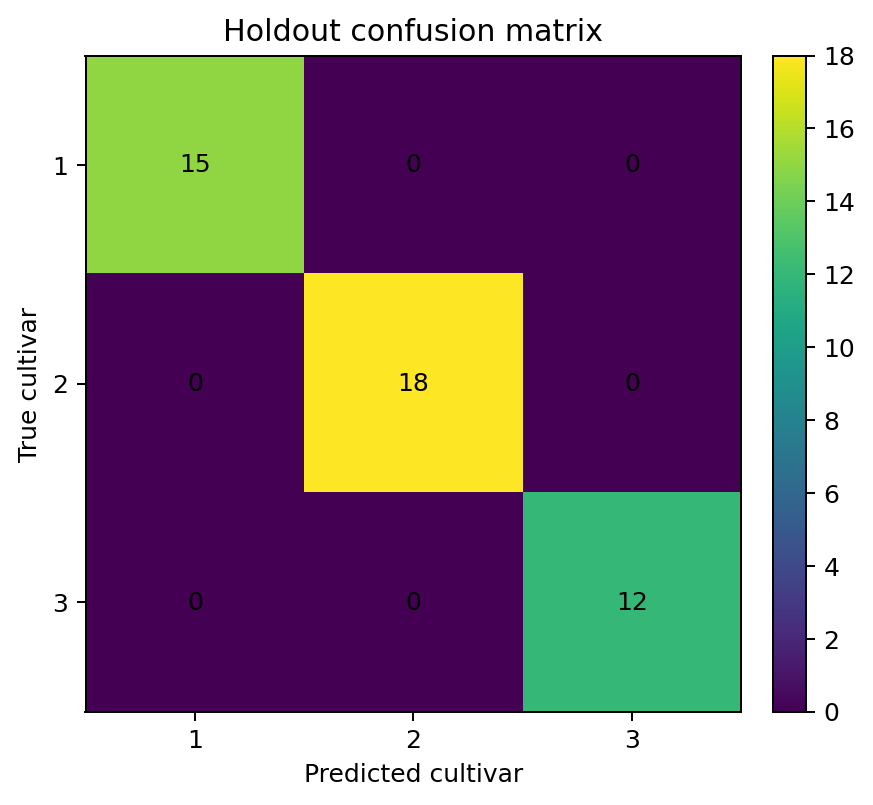

In [6]:
from IPython.display import Image, display
display(Image(filename=str(ROOT/'outputs/figures/confusion_matrix.png')))

## Interpretation

The holdout split happens to be classified perfectly, but a single split can be optimistic. The 10-fold result is therefore the preferred stability summary. The project treats classification as validation of the reduced discriminant structure, not as evidence of a universally perfect wine classifier.